# FIGURES_Regenerate: thesis data charts from the locked final run (V13 style)

Redraws every **data-bearing** thesis figure from the locked outputs, so each chart is traceable to code:
Figures 3.6, 3.7 and 3.8 (TweetEval EDA) and 5.1–5.6 (results).

**V13 change:** styling only — light fills with dark outlines, Times New Roman text, and an SVG copy of each chart. The data loading and the 63 logged values are unchanged from the previous version, so `FIGURE_VALUES.csv` is identical. The conceptual diagrams are drawn separately from Graphviz sources in `figures/diagrams/`.

Inputs (read-only): `LJMU_FINAL_EXPERIMENT_RUN/data/tweeteval_*_final.parquet` and `results/*.csv` written by the locked notebooks.
Output: PNGs (300 dpi) and SVGs plus `FIGURE_VALUES.csv`, in `figures/thesis_regenerated/`.

In [1]:
from google.colab import drive; drive.mount('/content/drive')
!pip -q install emoji
import os, re, glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, emoji
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN')
RES, DATA = ROOT/'results', ROOT/'data'
OUT = ROOT/'figures'/'thesis_regenerated'; OUT.mkdir(parents=True, exist_ok=True)
# Times New Roman is named first; Liberation Serif has identical metrics, so layout is the same on systems without it.
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'], 'svg.fonttype': 'none',
    'font.size': 10.5, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'text.color': '#1a1a1a', 'axes.labelcolor': '#1a1a1a', 'xtick.color': '#1a1a1a', 'ytick.color': '#1a1a1a', 'axes.edgecolor': '#333333', 'legend.frameon': False})
# Light fills with darker outlines of the same hue
CLS = {0: ('#F4C2C2', '#A33A3A'), 1: ('#DDDDDD', '#6E6E6E'), 2: ('#C4E3D9', '#2E7D6E')}
GRP = {'reference-unmarked': ('#C9DCEF', '#2F5C8A'), 'emoji-heavy': ('#C4E3D9', '#2E7D6E'), 'slang-heavy': ('#F9DFAE', '#A8720F'), 'sarcasm-indicated': ('#F3C9CE', '#A33A4B')}
TWO = [('#DCE6F0', '#5A7184'), ('#9DBCDD', '#2F5C8A')]
SRC_TGT = [('#C9DCEF', '#2F5C8A'), ('#F9DFAE', '#A8720F')]
VALUES = []
def log(fig, item, value): VALUES.append({'figure': fig, 'item': item, 'value': value})
def bar(ax, x, h, w, col, **k): return ax.bar(x, h, w, color=col[0], edgecolor=col[1], linewidth=0.9, **k)
def save(fig, name, w_px, h_px, rect=(0, 0, 1, 1)):
    fig.set_size_inches(w_px / 300, h_px / 300); fig.tight_layout(rect=rect)
    # Regression guard: legends for Figures 3.7 and 3.8 must not overlap chart axes.
    if name in ('Fig3_7_post_length.png', 'Fig3_8_markers.png'):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        for legend in fig.legends:
            for axis in fig.axes:
                assert not legend.get_window_extent(renderer).overlaps(axis.get_window_extent(renderer)), f'{name}: legend overlaps plot'
    fig.savefig(OUT/name, dpi=300); fig.savefig(OUT/name.replace('.png', '.svg')); plt.show(); print('saved', OUT/name)
def need(path):
    assert path.exists(), f'missing {path}'; return path

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 9.2 MB/s eta 0:00:00


## Chapter 3: TweetEval EDA (Figures 3.6–3.8)

In [ ]:
splits = {s: pd.read_parquet(need(DATA/f'tweeteval_{s}_final.parquet')) for s in ('train', 'validation', 'test')}
for s, d in splits.items(): print(s, len(d))
lab = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
# Figure 3.6 class distribution
fig, ax = plt.subplots(); w = 0.27
for i, k in enumerate((0, 1, 2)):
    sh = [100 * (d.label_id == k).mean() for d in splits.values()]
    n = [int((d.label_id == k).sum()) for d in splits.values()]
    bars = bar(ax, np.arange(3) + (i - 1) * w, sh, w, CLS[k], label=lab[k])
    for b, v, c_ in zip(bars, sh, n):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%\n({c_:,})', ha='center', va='bottom', fontsize=8.5)
    for s, v, c_ in zip(splits, sh, n): log('3.6', f'{s} {lab[k]}', f'{c_} ({v:.2f}%)')
ax.set_xticks(range(3)); ax.set_xticklabels([f'{s.title()}\n(N = {len(d):,})' for s, d in splits.items()])
ax.set_ylabel('Share of split (%)'); ax.set_ylim(0, 60)
# Keep the legend outside the plotting area so test bar labels are unobstructed.
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.02), frameon=False)
ax.set_title('TweetEval Sentiment Class Distribution by Official Split', pad=51)
save(fig, 'Fig3_6_class_distribution.png', 1830, 1017)

In [ ]:
# Figure 3.7 post length: left train vs test; right by class, all splits pooled
wc = {s: d.text.astype(str).str.split().str.len() for s, d in splits.items()}
fig, (a1, a2) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [1.05, 1]})
bins = np.arange(0, max(wc['train'].max(), wc['test'].max()) + 2)
for s, col, alpha in (('train', SRC_TGT[0], 0.85), ('test', SRC_TGT[1], 0.75)):
    a1.hist(wc[s], bins=bins, density=True, color=col[0], edgecolor=col[1], linewidth=0.5, alpha=alpha, label=f'{s.title()} (mean {wc[s].mean():.1f})')
    log('3.7', f'mean words {s}', round(wc[s].mean(), 2))
a1.set_xlabel('Whitespace words per post'); a1.set_ylabel('Density'); a1.set_title('(a) Train vs test', pad=8, fontweight='normal')
allp = pd.concat(splits.values()); allw = allp.text.astype(str).str.split().str.len()
data = [allw[allp.label_id == k] for k in (0, 1, 2)]
bp = a2.boxplot(data, widths=0.45, showfliers=False, patch_artist=True, medianprops={'color': '#1a1a1a', 'linewidth': 1.4})
for p_, k in zip(bp['boxes'], (0, 1, 2)): p_.set_facecolor(CLS[k][0]); p_.set_edgecolor(CLS[k][1])
for k, d_ in zip((0, 1, 2), data): log('3.7', f'pooled {lab[k]} Q1/med/Q3', np.percentile(d_, [25, 50, 75]).tolist())
a2.set_xticks([1, 2, 3]); a2.set_xticklabels([lab[k] for k in (0, 1, 2)]); a2.set_ylabel('Whitespace words per post'); a2.set_title('(b) By sentiment class, all splits pooled', pad=8, fontweight='normal')
# Reserve a separate header band for the legend; never place it over histogram bins.
legend_handles, legend_labels = a1.get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc='upper center',
           bbox_to_anchor=(0.26, 0.975), ncol=2, fontsize=8, frameon=False)
save(fig, 'Fig3_7_post_length.png', 1830, 864, rect=(0, 0, 1, 0.82))

In [ ]:
# Figure 3.8 informal-language markers. Uses the frozen tagger's own counts where it exposes them.
import sys; sys.path.insert(0, '/content')
try:
    import final_thesis_utils as ftu
except ImportError:
    ftu = None
if ftu is None:
    try:
        import io, google.auth
        from google.colab import auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        auth.authenticate_user(); creds, _ = google.auth.default()
        req = build('drive', 'v3', credentials=creds, cache_discovery=False).files().get_media(fileId='14KfwtUf2zSd_jlW7i-6K8XgBJ62Aqk02')
        with io.FileIO('/content/final_thesis_utils.py', 'wb') as fh:
            dl = MediaIoBaseDownload(fh, req); done = False
            while not done: _, done = dl.next_chunk()
        import final_thesis_utils as ftu
    except Exception as ex:
        print('could not load final_thesis_utils:', ex)
if ftu is None:
    print('final_thesis_utils not available: slang/sarcasm will use fallbacks (values may differ slightly)')
rows = {}
for s, d in splits.items():
    t = ftu.tag_subgroups(d.copy(), 'text') if ftu is not None else d.copy()
    emo = d.text.astype(str).map(lambda x: emoji.emoji_count(x) > 0)
    scol = next((c for c in t.columns if 'slang' in c.lower() and 'count' in c.lower()), None)
    sarc = next((c for c in t.columns if 'sarcas' in c.lower() and c != 'subgroup'), None)
    if scol: sl = t[scol] > 0
    else:
        lex = {w.lower() for w in getattr(ftu, 'SLANG_TERMS', [])}
        sl = d.text.astype(str).str.lower().str.findall(r"[a-z0-9']+").map(lambda ws: any(w in lex for w in ws)); print('slang fallback tokeniser used')
    sa = t[sarc].astype(bool) if sarc else pd.Series(False, index=d.index)
    print(s, '| slang column:', scol, '| sarcasm column:', sarc)
    rows[s] = [100 * emo.mean(), 100 * sl.mean(), 100 * sa.mean()]
    for name, v in zip(('emoji', 'slang', 'sarcasm'), rows[s]): log('3.8', f'{s} {name} %', round(v, 2))
# Plot the frozen marker percentages with labels ABOVE their bars.
# The palette and marker calculations above are unchanged.
fig, ax = plt.subplots()
w = 0.27
split_names = list(splits)
for i, (name, group) in enumerate(zip(
    ('Any emoji', 'Any slang-lexicon term', 'Sarcasm-cue match'),
    ('emoji-heavy', 'slang-heavy', 'sarcasm-indicated'),
)):
    values = [rows[s][i] for s in split_names]
    bars = bar(
        ax, np.arange(len(split_names)) + (i - 1) * w,
        values, w, GRP[group], label=name
    )
    # A point-based offset works for tall bars and short/zero-height bars alike.
    ax.bar_label(
        bars,
        labels=[f'{value:.2f}%' for value in values],
        label_type='edge', padding=5, fontsize=8,
        color='#1a1a1a'
    )

ax.set_xticks(np.arange(len(split_names)))
ax.set_xticklabels([s.title() for s in split_names])
ax.set_ylabel('Posts containing marker (%)')
ax.set_ylim(0, max(9, max(max(v) for v in rows.values()) + 1.2))
ax.yaxis.grid(True, linestyle='--', alpha=0.15)
ax.set_axisbelow(True)

# Keep the legend in its own header band, outside the plotted bars and labels.
# The original Figure 3.8 has no in-chart title. Word supplies its numbered caption.
legend_handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc='upper center',
           bbox_to_anchor=(0.5, 0.98), ncol=3, fontsize=8, frameon=False)
fig.text(
    0.01, 0.02,
    'Train and validation contain no emoji at all; '
    'all 809 emoji-bearing posts are in the test split.',
    fontsize=8.5, style='italic'
)
# The existing save helper enforces 1830 x 969 px and makes PNG + SVG.
save(fig, 'Fig3_8_markers.png', 1830, 969, rect=(0, 0.07, 1, 0.90))


## Chapter 5: results (Figures 5.1–5.6), read from the locked result CSVs

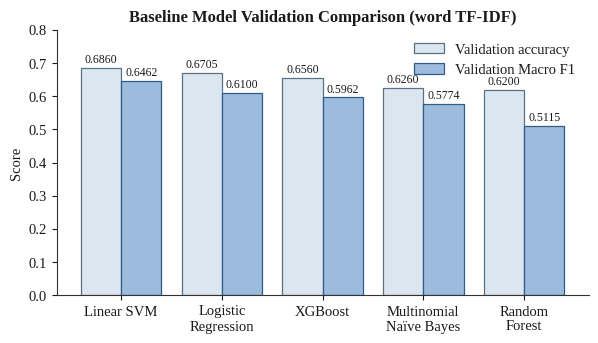

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_1_baseline_validation.png


In [5]:
# Figure 5.1 baseline validation
NAMES = {'linearsvm': 'Linear SVM', 'logisticregression': 'Logistic\nRegression', 'xgboost': 'XGBoost', 'multinomialnb': 'Multinomial\nNaïve Bayes',
         'multinomialnaivebayes': 'Multinomial\nNaïve Bayes', 'naivebayes': 'Multinomial\nNaïve Bayes', 'randomforest': 'Random\nForest'}
disp = lambda m: NAMES.get(re.sub(r'[^a-z]', '', str(m).lower().replace('ï', 'i')), str(m))
b = pd.read_csv(need(RES/'F02_baseline_validation.csv')).sort_values('Macro F1', ascending=False)
fig, ax = plt.subplots(); x = np.arange(len(b))
for off, col, sty, lab_ in ((-0.2, 'Accuracy', TWO[0], 'Validation accuracy'), (0.2, 'Macro F1', TWO[1], 'Validation Macro F1')):
    bars = bar(ax, x + off, b[col], 0.4, sty, label=lab_)
    for bb, v in zip(bars, b[col]): ax.text(bb.get_x() + bb.get_width() / 2, v + 0.006, f'{v:.4f}', ha='center', va='bottom', fontsize=8.5)
for _, r in b.iterrows(): log('5.1', r.Model, f"acc {r.Accuracy:.6f} / macroF1 {r['Macro F1']:.6f}")
ax.set_xticks(x); ax.set_xticklabels([disp(m) for m in b.Model]); ax.set_ylim(0, 0.8); ax.set_ylabel('Score'); ax.legend(loc='upper right')
ax.set_title('Baseline Model Validation Comparison (word TF-IDF)'); save(fig, 'Fig5_1_baseline_validation.png', 1830, 1065)

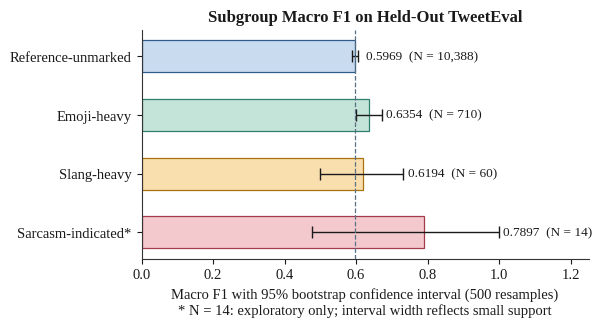

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_2_subgroup_macro_f1.png


In [6]:
# Figure 5.2 subgroup Macro F1 with bootstrap intervals
p = pd.read_csv(need(RES/'F05_RQ1_subgroup_performance.csv')).set_index('Subgroup')
order = ['reference-unmarked', 'emoji-heavy', 'slang-heavy', 'sarcasm-indicated']; p = p.loc[order]
fig, ax = plt.subplots(); y = np.arange(len(p))[::-1]
for yy, (g, r) in zip(y, p.iterrows()):
    ax.barh(yy, r['Macro F1'], 0.55, color=GRP[g][0], edgecolor=GRP[g][1], linewidth=0.9)
    ax.errorbar(r['Macro F1'], yy, xerr=[[r['Macro F1'] - r['Macro F1 CI Low']], [r['Macro F1 CI High'] - r['Macro F1']]], fmt='none', ecolor='#1a1a1a', capsize=4, linewidth=1)
    xt = r['Macro F1'] + 0.03 if g == 'reference-unmarked' else r['Macro F1 CI High'] + 0.012
    ax.text(xt, yy, f"{r['Macro F1']:.4f}  (N = {int(r.N):,})", va='center', fontsize=9.5)
    log('5.2', g, f"{r['Macro F1']:.6f} [{r['Macro F1 CI Low']:.6f}, {r['Macro F1 CI High']:.6f}] N={int(r.N)}")
ax.axvline(p.loc['reference-unmarked', 'Macro F1'], color='#5A7184', linestyle='--', linewidth=0.9)
ax.set_yticks(y); ax.set_yticklabels([g.capitalize() + ('*' if g.startswith('sarc') else '') for g in order]); ax.set_xlim(0, 1.25)
ax.set_xlabel('Macro F1 with 95% bootstrap confidence interval (500 resamples)\n* N = 14: exploratory only; interval width reflects small support')
ax.set_title('Subgroup Macro F1 on Held-Out TweetEval'); save(fig, 'Fig5_2_subgroup_macro_f1.png', 1830, 1017)

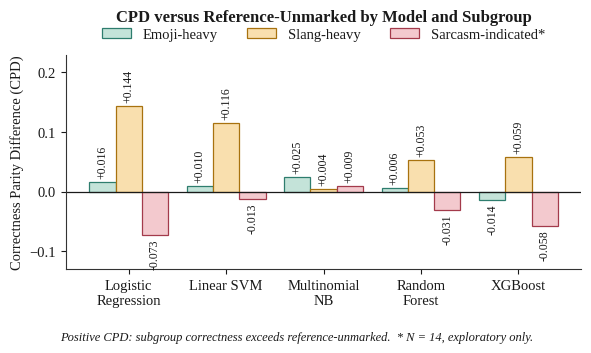

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_3_cpd.png


In [7]:
# Figure 5.3 CPD by model and subgroup (labels rounded once, from full-precision values)
c = pd.read_csv(need(RES/'F05_RQ2_CPD_CRR_five_models.csv'))
models = ['LogisticRegression', 'LinearSVM', 'MultinomialNB', 'RandomForest', 'XGBoost']
groups = [('emoji-heavy', 'Emoji-heavy'), ('slang-heavy', 'Slang-heavy'), ('sarcasm-indicated', 'Sarcasm-indicated*')]
fig, ax = plt.subplots(); x = np.arange(len(models))
for i, (g, name) in enumerate(groups):
    v = [float(c[(c.Model == m) & (c.Subgroup == g)].CPD.iloc[0]) for m in models]
    bars = bar(ax, x + (i - 1) * 0.27, v, 0.27, GRP[g], label=name)
    for bb, val, m in zip(bars, v, models):
        ax.text(bb.get_x() + bb.get_width() / 2, val + (0.006 if val >= 0 else -0.006), f'{val:+.3f}', rotation=90, ha='center', va='bottom' if val >= 0 else 'top', fontsize=8.5)
        log('5.3', f'{m} {g}', round(val, 6))
ax.axhline(0, color='#1a1a1a', linewidth=0.9); ax.set_xticks(x)
ax.set_xticklabels(['Logistic\nRegression', 'Linear SVM', 'Multinomial\nNB', 'Random\nForest', 'XGBoost'])
ax.set_ylim(-0.13, 0.23); ax.set_ylabel('Correctness Parity Difference (CPD)')
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0))
ax.set_title('CPD versus Reference-Unmarked by Model and Subgroup', pad=24)
fig.text(0.12, 0.01, 'Positive CPD: subgroup correctness exceeds reference-unmarked.  * N = 14, exploratory only.', fontsize=9, style='italic')
save(fig, 'Fig5_3_cpd.png', 1830, 1050, rect=(0, 0.06, 1, 1))

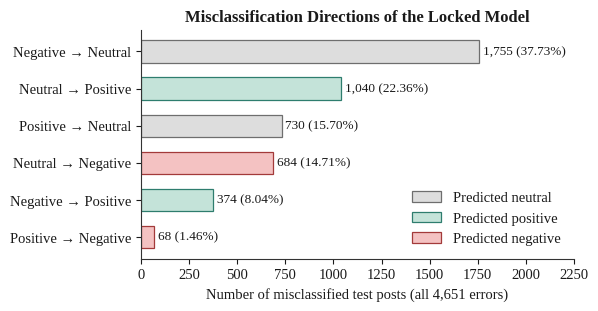

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_4_error_directions.png


In [8]:
# Figure 5.4 error directions (bars coloured by the predicted class)
e = pd.read_csv(need(RES/'F06_all_error_directions.csv')).sort_values('N Errors')
fig, ax = plt.subplots(); seen = set(); PRED = {'negative': 0, 'neutral': 1, 'positive': 2}
for i, (_, r) in enumerate(e.iterrows()):
    pred = str(r['Error Direction']).split('->')[-1].strip().lower(); k = PRED[pred]
    ax.barh(i, r['N Errors'], 0.6, color=CLS[k][0], edgecolor=CLS[k][1], linewidth=0.9, label=None if pred in seen else f'Predicted {pred}'); seen.add(pred)
    ax.text(r['N Errors'] + 20, i, f"{int(r['N Errors']):,} ({r['% of All Errors']:.2f}%)", va='center', fontsize=9.5)
    log('5.4', r['Error Direction'], f"{int(r['N Errors'])} ({r['% of All Errors']:.4f}%)")
ax.set_yticks(range(len(e))); ax.set_yticklabels(e['Error Direction'].str.replace(' -> ', ' → ').str.title())
ax.set_xlim(0, 2250); ax.set_xlabel(f"Number of misclassified test posts (all {int(e['N Errors'].sum()):,} errors)")
handles, labels = ax.get_legend_handles_labels(); order_ = [labels.index(f'Predicted {p_}') for p_ in ('neutral', 'positive', 'negative') if f'Predicted {p_}' in labels]
ax.legend([handles[i] for i in order_], [labels[i] for i in order_], loc='lower right')
ax.set_title('Misclassification Directions of the Locked Model'); save(fig, 'Fig5_4_error_directions.png', 1830, 969)

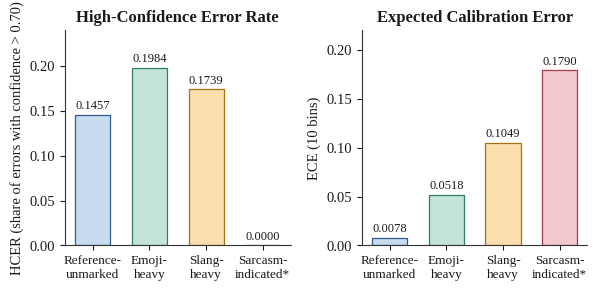

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_5_hcer_ece.png


In [9]:
# Figure 5.5 HCER and ECE by subgroup
cc = pd.read_csv(need(RES/'F07_confidence_calibration_by_subgroup.csv')).set_index('Subgroup').loc[['reference-unmarked', 'emoji-heavy', 'slang-heavy', 'sarcasm-indicated']]
fig, axs = plt.subplots(1, 2)
for ax, col, title, yl, top in ((axs[0], 'HCER', 'High-Confidence Error Rate', 'HCER (share of errors with confidence > 0.70)', 0.24),
                                (axs[1], 'ECE', 'Expected Calibration Error', 'ECE (10 bins)', 0.22)):
    for i, (g, v) in enumerate(cc[col].items()):
        bar(ax, i, v, 0.62, GRP[g]); ax.text(i, v + top * 0.012, f'{v:.4f}', ha='center', va='bottom', fontsize=9)
    for g, v in cc[col].items(): log('5.5', f'{col} {g}', round(float(v), 6))
    ax.set_xticks(range(4)); ax.set_xticklabels(['Reference-\nunmarked', 'Emoji-\nheavy', 'Slang-\nheavy', 'Sarcasm-\nindicated*'], fontsize=9.5)
    ax.set_ylabel(yl); ax.set_title(title); ax.set_ylim(0, top)
save(fig, 'Fig5_5_hcer_ece.png', 1830, 908)


SemEval-2014 columns: ['Model', 'Accuracy', 'Macro F1', 'Weighted F1', 'Macro Precision', 'Macro Recall', 'MCC', 'Cohen Kappa', 'Brier', 'Target Dataset', 'Condition', 'Evaluation Unit', 'Target N', 'Unique Sentences', 'TweetEval Source 3-Class N', 'TweetEval Source 3-Class Accuracy', 'TweetEval Source 3-Class Macro F1', 'Accuracy Delta vs TweetEval Source', 'Macro F1 Delta vs TweetEval Source']
Model                                    FinalSelectedPipeline
Accuracy                                              0.648464
Macro F1                                              0.573551
Weighted F1                                           0.662279
Macro Precision                                       0.610435
Macro Recall                                          0.576669
MCC                                                   0.403031
Cohen Kappa                                           0.392975
Brier                                                 0.149901
Target Dataset                   

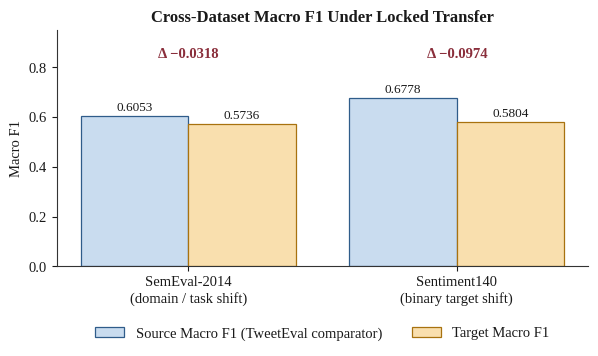

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_6_cross_dataset.png


In [10]:
# Figure 5.6 cross-dataset Macro F1 (robust column selection + self-check)
def find_col(df, *patterns, exclude=()):
    for c_ in df.columns:
        if all(re.search(p_, c_, re.I) for p_ in patterns) and not any(re.search(x, c_, re.I) for x in exclude):
            return c_
    return None

rows = []
for f, name in (('F10_SemEval_domain_task_shift.csv', 'SemEval-2014'),
                ('F09_Sentiment140_binary_robustness.csv', 'Sentiment140')):
    d = pd.read_csv(need(RES/f)); r = d.iloc[0]
    print(f'\n{name} columns:', list(d.columns)); print(r.to_string())
    tgt_col = (next((c_ for c_ in d.columns if c_.strip().lower() == 'macro f1'), None)
               or find_col(d, 'target', 'macro', 'f1')
               or find_col(d, 'macro', 'f1', exclude=('source', 'delta', 'weighted', 'ci', 'gap')))
    src_col = find_col(d, 'source', 'macro', 'f1') or find_col(d, 'comparator', 'macro')
    assert tgt_col and src_col, f'could not identify columns: target={tgt_col}, source={src_col}'
    tgt, src = float(r[tgt_col]), float(r[src_col])
    dcol = find_col(d, 'delta', 'macro')
    if dcol: assert abs((tgt - src) - float(r[dcol])) < 1e-9, f'delta check failed: {tgt - src} vs {r[dcol]}'
    print(f'-> using target="{tgt_col}" ({tgt:.6f}), source="{src_col}" ({src:.6f})' + (f', delta matches "{dcol}"' if dcol else ''))
    rows.append((name, src, tgt)); log('5.6', name, f'source {src:.6f} target {tgt:.6f} delta {tgt - src:+.6f}')

fig, ax = plt.subplots()
XL = {'SemEval-2014': 'SemEval-2014\n(domain / task shift)', 'Sentiment140': 'Sentiment140\n(binary target shift)'}
for i, (name, s, t) in enumerate(rows):
    bar(ax, i - 0.2, s, 0.4, SRC_TGT[0], label='Source Macro F1 (TweetEval comparator)' if i == 0 else None)
    bar(ax, i + 0.2, t, 0.4, SRC_TGT[1], label='Target Macro F1' if i == 0 else None)
    ax.text(i - 0.2, s + 0.008, f'{s:.4f}', ha='center', va='bottom', fontsize=9.5); ax.text(i + 0.2, t + 0.008, f'{t:.4f}', ha='center', va='bottom', fontsize=9.5)
    ax.text(i, 0.84, f'Δ {t - s:+.4f}'.replace('-', '−'), ha='center', fontsize=10.5, fontweight='bold', color='#8A2E3B')
ax.set_xticks(range(len(rows))); ax.set_xticklabels([XL.get(r[0], r[0]) for r in rows]); ax.set_ylim(0, 0.95); ax.set_ylabel('Macro F1')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.2)); ax.set_title('Cross-Dataset Macro F1 Under Locked Transfer')
save(fig, 'Fig5_6_cross_dataset.png', 1830, 1137)

In [11]:
pd.DataFrame(VALUES).to_csv(OUT/'FIGURE_VALUES.csv', index=False)
print(pd.DataFrame(VALUES).to_string()); print('\nAll figures and FIGURE_VALUES.csv saved to', OUT)

   figure                                  item                                            value
0     3.6                        train Negative                                    7093 (15.55%)
1     3.6                   validation Negative                                     312 (15.60%)
2     3.6                         test Negative                                    3972 (32.33%)
3     3.6                         train Neutral                                   20673 (45.32%)
4     3.6                    validation Neutral                                     869 (43.45%)
5     3.6                          test Neutral                                    5937 (48.33%)
6     3.6                        train Positive                                   17849 (39.13%)
7     3.6                   validation Positive                                     819 (40.95%)
8     3.6                         test Positive                                    2375 (19.33%)
9     3.7                     